# Regularization and Gradient Descent Exercises
![UnderOverFit.png](../assets/UnderOverFit.png)


# Obiectivele învățării

- Explicarea funcțiilor de cost, regularizarea, selectarea caracteristicilor și hiperparametrii
- Rezumarea algoritmilor de optimizare statistică complexă, cum ar fi coborârea gradientului și aplicarea sa la regresia liniară


## Introducere

Vom începe cu un scurt tutorial despre regresie, caracteristici polinomiale și regularizare, bazat pe un set de date foarte simplu, rar, care conține o coloană de date `x` și date zgomotoase asociate `y`. Fișierul de date se numește `X_Y_Sinusoid_Data.csv`.

In [70]:
from __future__ import print_function
import os
data_path = ['..', 'data'] if os.path.exists(os.path.join('..', 'data')) else ['data']

%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import PolynomialFeatures, MinMaxScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.linear_model import RidgeCV, LassoCV, ElasticNetCV, SGDRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
import warnings
from scipy.linalg import LinAlgWarning
warnings.filterwarnings('ignore', category=LinAlgWarning)

## Întrebare 1

* Importați datele.

* De asemenea, generați aproximativ 100 de puncte de date x egal distanțate pe intervalul 0-1. Folosind aceste puncte, calculați datele y care reprezintă „adevărul de bază” (funcția reală) din ecuația: $y = \sin(2\pi x)$

* Reprezentați grafic datele rarefiate (`x` vs `y`) și datele calculate („reale”).

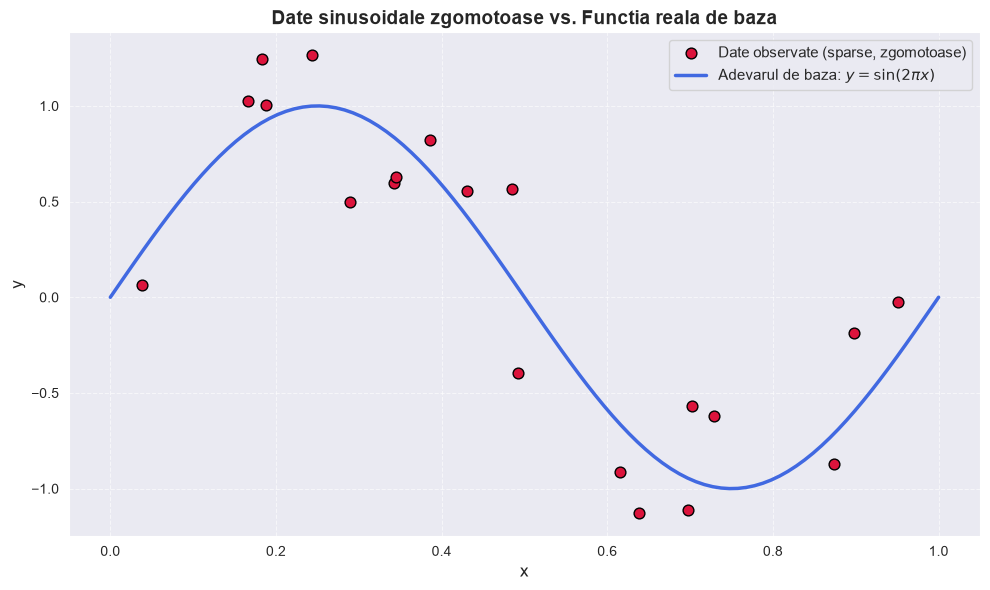

In [71]:
# 1. Citirea datelor din fisierul X_Y_Sinusoid_Data.csv
file_path = os.sep.join(data_path + ['X_Y_Sinusoid_Data.csv'])
sin_data = pd.read_csv(file_path)
X = sin_data[['x']]
y = sin_data['y']

# 2. Generarea a 100 de puncte egal distantate pe [0, 1] si calcularea curbei reale
x_real = np.linspace(0, 1, 100)
y_real = np.sin(2 * np.pi * x_real)

# 3. Reprezentarea grafica a datelor observate si a functiei sinusoidale teoretice reale
plt.figure(figsize=(10, 6))
plt.scatter(sin_data['x'], sin_data['y'], color='crimson', edgecolor='black', s=60, label='Date observate (sparse, zgomotoase)', zorder=5)
plt.plot(x_real, y_real, color='royalblue', linewidth=2.5, label=r'Adevarul de baza: $y = \sin(2\pi x)$')
plt.title('Date sinusoidale zgomotoase vs. Functia reala de baza', fontsize=14, fontweight='bold')
plt.xlabel('x', fontsize=12)
plt.ylabel('y', fontsize=12)
plt.legend(fontsize=11, loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## Întrebarea 2

* Folosind clasa `PolynomialFeatures` din biblioteca de preprocesare Scikit-learn, creați caracteristici polinomiale de ordinul 20.
* Adaptați aceste date folosind regresia liniară.
* Reprezentați grafic valoarea prezisă rezultată în comparație cu datele calculate.

Rețineți că `PolynomialFeatures` necesită fie un cadru de date (cu o coloană, nu o serie), fie o matrice 2D de dimensiune (`X`, 1), unde `X` este lungimea.

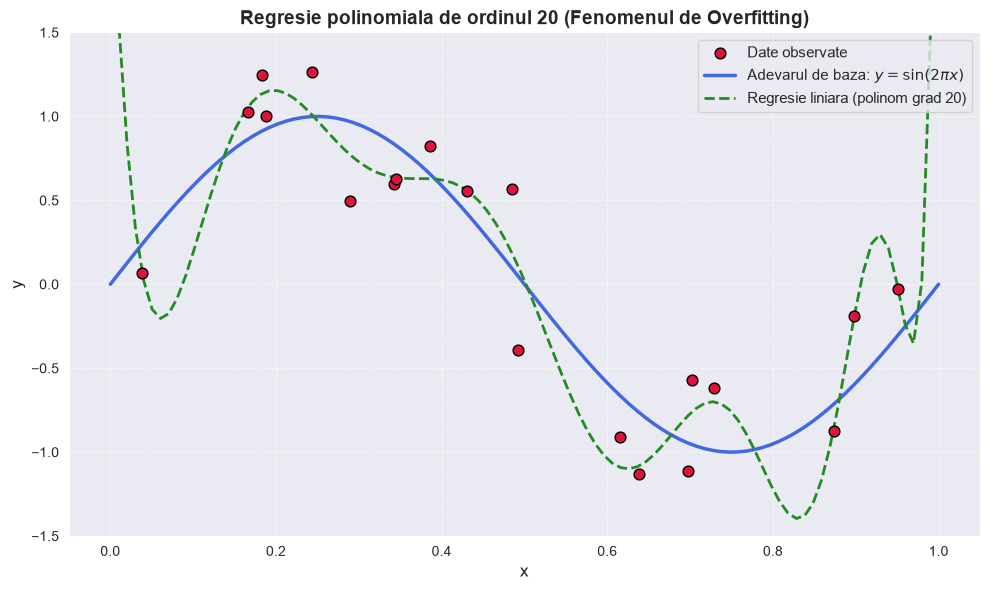

In [72]:
# 1. Crearea caracteristicilor polinomiale de grad 20
poly = PolynomialFeatures(degree=20, include_bias=False)
X_poly = poly.fit_transform(X)

# 2. Potrivirea regresiei liniare simple (fara regularizare)
lr = LinearRegression()
lr.fit(X_poly, y)

# 3. Predictia valorilor pe setul dens de 100 de puncte x_real
X_real_poly = poly.transform(pd.DataFrame({'x': x_real}))
y_poly_pred = lr.predict(X_real_poly)

# 4. Reprezentarea grafica a predictiilor vs functia reala
plt.figure(figsize=(10, 6))
plt.scatter(sin_data['x'], sin_data['y'], color='crimson', edgecolor='black', s=60, label='Date observate', zorder=5)
plt.plot(x_real, y_real, color='royalblue', linewidth=2.5, label=r'Adevarul de baza: $y = \sin(2\pi x)$')
plt.plot(x_real, y_poly_pred, color='forestgreen', linestyle='--', linewidth=2, label='Regresie liniara (polinom grad 20)')
plt.ylim(-1.5, 1.5)
plt.title('Regresie polinomiala de ordinul 20 (Fenomenul de Overfitting)', fontsize=14, fontweight='bold')
plt.xlabel('x', fontsize=12)
plt.ylabel('y', fontsize=12)
plt.legend(fontsize=11, loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## Întrebare 3

* Efectuați regresia pe baza datelor cu caracteristici polinomiale utilizând regresia Ridge ($\alpha=0.001$) și regresia Lasso ($\alpha=0.0001$).
* Reprezentați grafic rezultatele, așa cum s-a făcut la întrebarea 1.
* De asemenea, reprezentați grafic magnitudinea coeficienților obținuți din aceste regresii și comparați-i cu cei obținuți din regresia liniară din întrebarea anterioară. Coeficienții regresiei liniare vor necesita probabil un grafic separat (sau propria axă y) din cauza magnitudinii lor mari.

Ce vă spune magnitudinea comparativ mare a datelor cu privire la rolul regularizării?

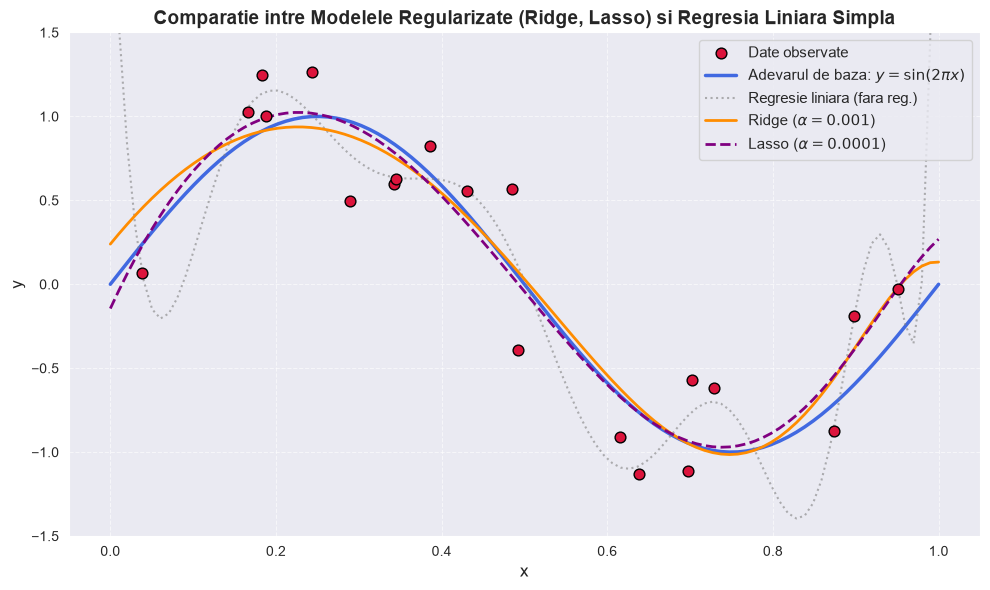

In [73]:
# 1. Ajustarea modelului Ridge (regularizare L2 cu alpha=0.001)
rr = Ridge(alpha=0.001, random_state=42)
rr.fit(X_poly, y)
y_ridge_pred = rr.predict(X_real_poly)

# 2. Ajustarea modelului Lasso (regularizare L1 cu alpha=0.0001)
lassor = Lasso(alpha=0.0001, max_iter=100000, random_state=42)
lassor.fit(X_poly, y)
y_lasso_pred = lassor.predict(X_real_poly)

# 3. Reprezentarea grafica a modelelor regularizate vs adevarul de baza si regresia liniara
plt.figure(figsize=(10, 6))
plt.scatter(sin_data['x'], sin_data['y'], color='crimson', edgecolor='black', s=60, label='Date observate', zorder=5)
plt.plot(x_real, y_real, color='royalblue', linewidth=2.5, label=r'Adevarul de baza: $y = \sin(2\pi x)$')
plt.plot(x_real, y_poly_pred, color='gray', linestyle=':', linewidth=1.5, alpha=0.6, label='Regresie liniara (fara reg.)')
plt.plot(x_real, y_ridge_pred, color='darkorange', linewidth=2, label=r'Ridge ($\alpha=0.001$)')
plt.plot(x_real, y_lasso_pred, color='purple', linestyle='--', linewidth=2, label=r'Lasso ($\alpha=0.0001$)')
plt.ylim(-1.5, 1.5)
plt.title('Comparatie intre Modelele Regularizate (Ridge, Lasso) si Regresia Liniara Simpla', fontsize=14, fontweight='bold')
plt.xlabel('x', fontsize=12)
plt.ylabel('y', fontsize=12)
plt.legend(fontsize=11, loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [74]:
# Colectarea marimilor absolute ale coeficientilor pentru fiecare model
coefficients = pd.DataFrame()
coefficients['linear regression'] = lr.coef_.ravel()
coefficients['ridge regression'] = rr.coef_.ravel()
coefficients['lasso regression'] = lassor.coef_.ravel()
coefficients = coefficients.apply(np.abs)

print("Statistici descriptive pentru magnitudinea coeficientilor:")
display(coefficients.describe())  # Diferenta uriasa de scala intre regresia liniara simpla si cele regularizate

Statistici descriptive pentru magnitudinea coeficientilor:


,linear regression,ridge regression,lasso regression
count,20.000000,20.000000,20.000000
mean,10993.215472,2.277867,2.798440
std,6619.669433,2.931594,6.920062
min,105.319954,0.123363,0.000000
25%,6950.834788,0.508969,0.000000
50%,11729.964672,1.100772,0.000000
75%,15308.156167,3.180162,0.275864
max,23169.126273,12.429635,25.359652


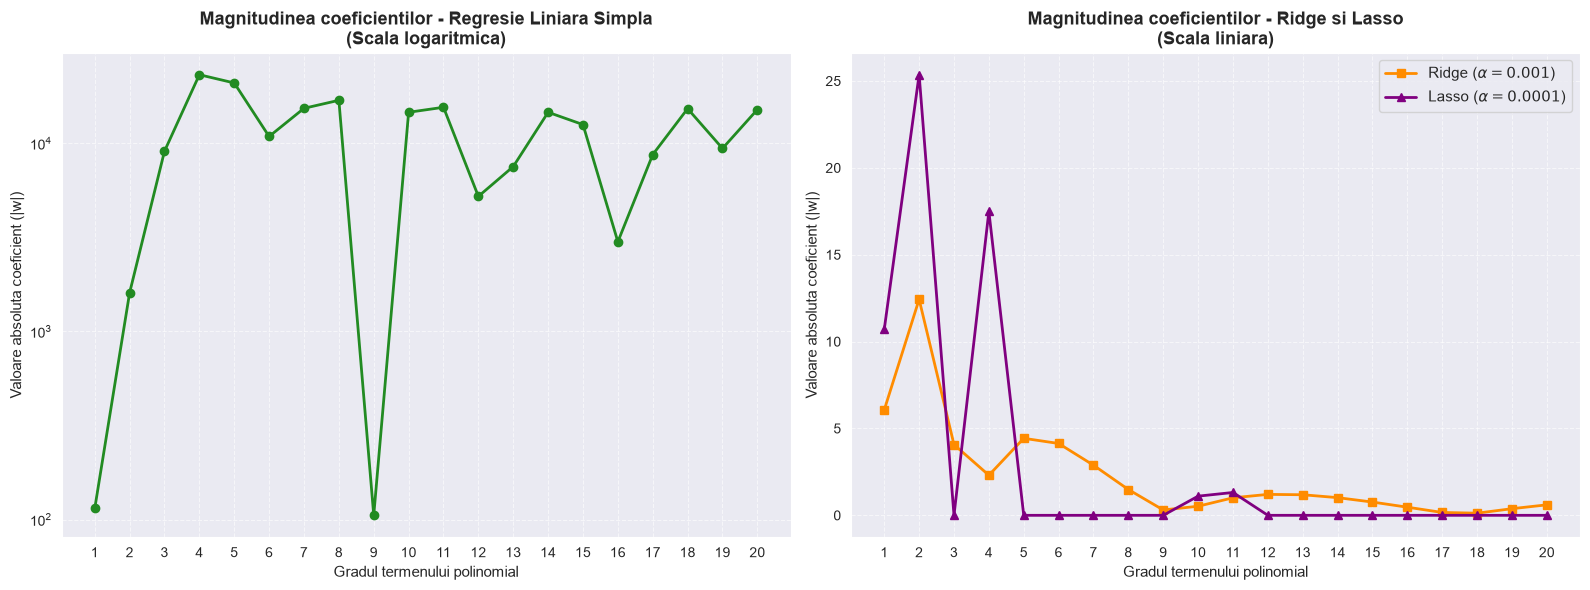

In [75]:
# Reprezentarea grafica comparativa a coeficientilor
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Coeficientii regresiei liniare simple (scara logaritmica, deoarece magnitudinile sunt uriase)
axes[0].plot(range(1, 21), coefficients['linear regression'], marker='o', color='forestgreen', linewidth=2, markersize=6)
axes[0].set_title('Magnitudinea coeficientilor - Regresie Liniara Simpla\n(Scala logaritmica)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Gradul termenului polinomial', fontsize=11)
axes[0].set_ylabel('Valoare absoluta coeficient (|w|)', fontsize=11)
axes[0].set_yscale('log')
axes[0].set_xticks(range(1, 21))
axes[0].grid(True, linestyle='--', alpha=0.6)

# Subplot 2: Coeficientii modelelor regularizate Ridge si Lasso (scara liniara)
axes[1].plot(range(1, 21), coefficients['ridge regression'], marker='s', color='darkorange', label=r'Ridge ($\alpha=0.001$)', linewidth=2, markersize=6)
axes[1].plot(range(1, 21), coefficients['lasso regression'], marker='^', color='purple', label=r'Lasso ($\alpha=0.0001$)', linewidth=2, markersize=6)
axes[1].set_title('Magnitudinea coeficientilor - Ridge si Lasso\n(Scala liniara)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Gradul termenului polinomial', fontsize=11)
axes[1].set_ylabel('Valoare absoluta coeficient (|w|)', fontsize=11)
axes[1].set_xticks(range(1, 21))
axes[1].legend(fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### Concluzie privind rolul regularizării (Întrebarea 3):

**Magnitudinea uriașă a coeficienților ne-regularizați**: În regresia liniară de gradul 20, coeficienții ating valori uriașe (zeci de mii sau chiar ordine de mărime mult mai mari; valoarea exactă depinde de mediul numeric, fiindcă sistemul este aproape singular — vezi tabelul de statistici de mai sus), față de maximum ~12 la Ridge și ~25 la Lasso. Aceștia au semne alternante uriașe care se anulează reciproc, permițând modelului să treacă forțat prin punctele observate (overfitting extrem). Varianța modelului devine astfel excesiv de mare, iar curba prezisă oscilează necontrolat în afara punctelor suport.

## Întrebarea 4

Pentru întrebările rămase, vom lucra cu [setul de date](https://www.kaggle.com/c/house-prices-advanced-regression-techniques) din lecția trecută, care se bazează pe prețurile locuințelor din Ames, Iowa. Există un număr mare de caracteristici - a se vedea exercițiile din săptămâna a treia pentru o discuție despre aceste caracteristici.

Pentru a începe:

* Importați datele cu Pandas, eliminați orice valori nule și o codificare fierbinte a categoriilor. Pot fi utilizate fie codificatoarele de caracteristici Scikit-learn, fie metoda Pandas `get_dummies`.
* Împărțiți datele în seturi de instruire și de testare. 
* Transformarea logaritmică a caracteristicilor distorsionate. 
* Se poate încerca scalarea, deși poate fi interesant să se vadă cât de bine funcționează regularizarea fără scalarea caracteristicilor.

In [76]:

house_data_path = os.sep.join(data_path + ['Ames_Housing_Sales.csv'])
house_data = pd.read_csv(house_data_path)

# Asigurarea ca variabila tinta 'SalePrice' este numerica si fara NaN
house_data['SalePrice'] = pd.to_numeric(house_data['SalePrice'], errors='coerce')
house_data = house_data.dropna(subset=['SalePrice'])

# Tratarea valorilor lipsa:
# 1. Pentru coloane numerice: completam cu mediana coloanei
num_cols = house_data.select_dtypes(include=[np.number]).columns.drop('SalePrice', errors='ignore')
for col in num_cols:
    if house_data[col].isnull().any():
        median_val = house_data[col].median()
        house_data[col] = house_data[col].fillna(median_val if not pd.isna(median_val) else 0)

# 2. Pentru coloane categorice: completam cu 'None'
cat_cols = house_data.select_dtypes(exclude=[np.number]).columns  # tot ce nu e numeric (object / str / category)
for col in cat_cols:
    house_data[col] = house_data[col].astype(object).fillna('None').astype(str)

print(f"Valori nule ramase in setul de date: {house_data.isnull().sum().sum()}")
print(f"Dimensiune dupa curatare si imputare: {house_data.shape}")

Valori nule ramase in setul de date: 0
Dimensiune dupa curatare si imputare: (1379, 80)


Creați o listă de date categoriale și codificați one-hot. Pandas one-hot encoder (`get_dummies`) funcționează bine cu date care sunt definite ca fiind categoriale.

In [77]:
# Codificarea one-hot a coloanelor categorice folosind pd.get_dummies
house_data = pd.get_dummies(house_data, drop_first=True)
print(f"Dimensiunea setului de date dupa codificarea one-hot: {house_data.shape}")

Dimensiunea setului de date dupa codificarea one-hot: (1379, 252)


Apoi, împărțiți datele în seturi de date de instruire și de testare.

In [78]:
# Impartirea datelor in 70% antrenare si 30% testare
train, test = train_test_split(house_data, test_size=0.3, random_state=42)
train = train.copy()
test = test.copy()

print(f"Dimensiune set de antrenare: {train.shape}")
print(f"Dimensiune set de testare: {test.shape}")

Dimensiune set de antrenare: (965, 252)
Dimensiune set de testare: (414, 252)


Există o serie de coloane care au caracteristici înclinate - li se poate aplica o transformare logaritmică. Rețineți că aceasta include `SalePrice`, predictorul nostru. Cu toate acestea, să o păstrăm așa cum este.

Transformați toate coloanele în care deviația este mai mare de 0,75, cu excepția „SalePrice”.

In [79]:
# Identificarea coloanelor numerice cu asimetrie (skewness) > 0.75 pe setul de antrenare, excluzand 'SalePrice'
num_cols_train = [c for c in train.select_dtypes(include=[np.number]).columns if c != 'SalePrice']
skew_vals = train[num_cols_train].skew()
skewed_cols = skew_vals[skew_vals > 0.75].index.tolist()

print(f"Numar caracteristici asimetrice identificate (skew > 0.75): {len(skewed_cols)}")
print("Exemple de caracteristici asimetrice:", skewed_cols[:5])

# Aplicarea transformarii log1p (log(1 + x)) pe caracteristicile asimetrice
for col in skewed_cols:
    train[col] = np.log1p(np.maximum(0, train[col]))
    test[col] = np.log1p(np.maximum(0, test[col]))

Numar caracteristici asimetrice identificate (skew > 0.75): 23
Exemple de caracteristici asimetrice: ['1stFlrSF', '2ndFlrSF', '3SsnPorch', 'BsmtFinSF1', 'BsmtFinSF2']


Separați datele dupa predictor

In [80]:
# Separarea variabilei tinta (SalePrice) de restul caracteristicilor predictive (X)
X_train = train.drop(columns=['SalePrice'])
y_train = train['SalePrice']

X_test = test.drop(columns=['SalePrice'])
y_test = test['SalePrice']

print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_test: {X_test.shape}, y_test: {y_test.shape}")

X_train: (965, 251), y_train: (965,)
X_test: (414, 251), y_test: (414,)


## Întrebare 5

* Scrieți o funcție **`rmse`** care primește valorile de adevăr și predicție și returnează eroarea medie pătratică. Utilizați funcția `mean_squared_error` de la sklearn.  
* Adaptați un model de regresie liniară de bază
* Tipăriți eroarea medie pătratică pentru acest model
* Reprezentați grafic prețul de vânzare previzionat față de cel real pe baza modelului.

Linear Regression Test RMSE: $78,634.29


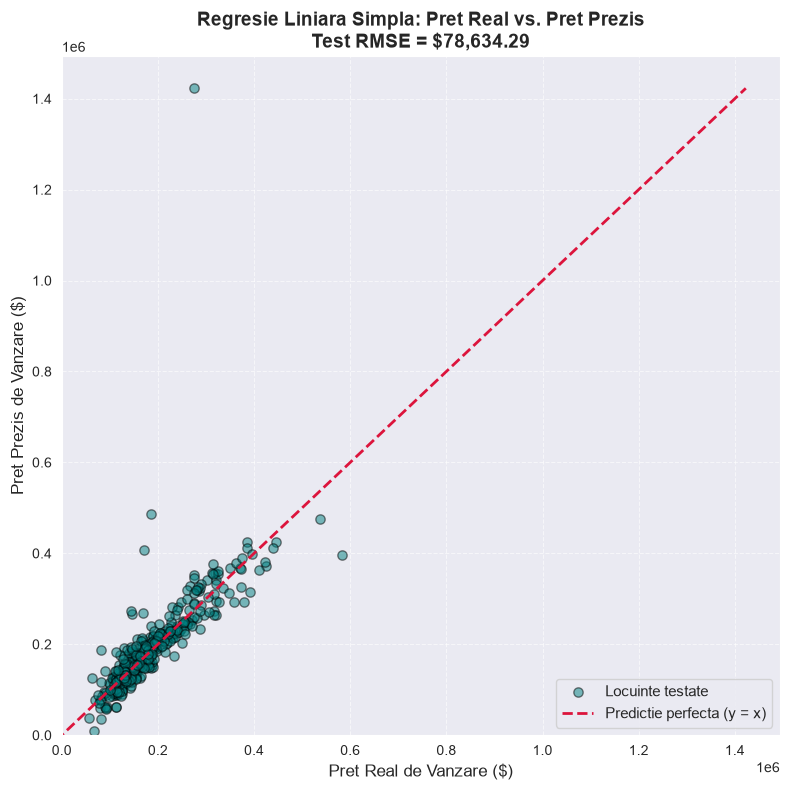

In [81]:
# 1. Definirea functiei rmse conform cerintei specifice
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

# 2. Antrenarea modelului de regresie liniara de baza (fara regularizare)
linear_reg = LinearRegression()
linear_reg.fit(X_train, y_train)

# 3. Predictia pe setul de testare si calcularea RMSE
y_pred_lr = linear_reg.predict(X_test)
rmse_lr = rmse(y_test, y_pred_lr)
print(f"Linear Regression Test RMSE: ${rmse_lr:,.2f}")

# 4. Reprezentarea grafica a pretului previzionat vs. pretul real
plt.figure(figsize=(8, 8))
plt.scatter(y_test, y_pred_lr, alpha=0.5, color='teal', edgecolor='black', s=45, label='Locuinte testate')
min_p = min(y_test.min(), y_pred_lr.min())
max_p = max(y_test.max(), y_pred_lr.max())
plt.plot([min_p, max_p], [min_p, max_p], color='crimson', linestyle='--', linewidth=2, label='Predictie perfecta (y = x)')
plt.title(f'Regresie Liniara Simpla: Pret Real vs. Pret Prezis\nTest RMSE = ${rmse_lr:,.2f}', fontsize=14, fontweight='bold')
plt.xlabel('Pret Real de Vanzare ($)', fontsize=12)
plt.ylabel('Pret Prezis de Vanzare ($)', fontsize=12)
plt.xlim(0, max_p * 1.05)
plt.ylim(0, max_p * 1.05)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## Întrebarea 6

Regresia Ridge utilizează normalizarea L2 pentru a reduce magnitudinea coeficienților. Acest lucru poate fi util în situații în care există o varianță ridicată. Funcțiile de regularizare din Scikit-learn conțin fiecare versiuni care au validarea încrucișată încorporată.

* Adaptați un model Ridge regulat (nevalidat încrucișat) la o gamă de valori $\alpha$ și reprezentați grafic RMSE utilizând funcția de eroare pe care ați creat-o mai sus.
* Utilizați $$[0.005, 0.05, 0.1, 0.3, 1, 3, 5, 10, 15, 30, 80]$$ ca interval de alphas.
* Apoi repetați ajustarea modelelor Ridge folosind gama de valori $\alpha$ din secțiunea anterioară. Comparați rezultatele.

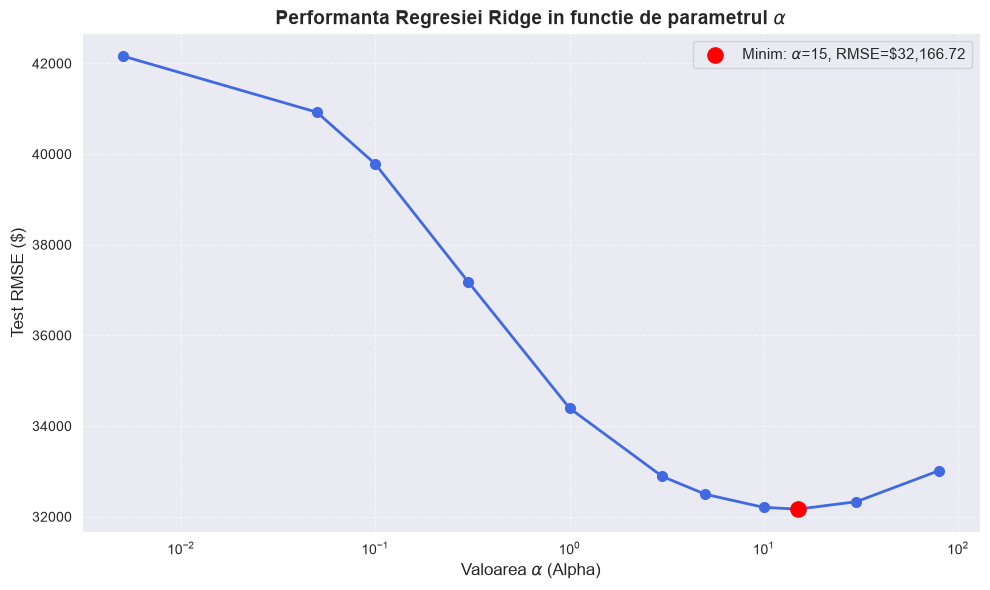

,Alpha,Test RMSE
0,0.005,42163.877433
1,0.050,40923.854447
2,0.100,39780.744304
3,0.300,37188.044019
4,1.000,34394.971406
5,3.000,32889.602290
6,5.000,32495.098545
7,10.000,32205.825151
8,15.000,32166.724797
9,30.000,32331.257943


In [82]:
# 1. Intervalul de valori alpha specificat
alphas_ridge = [0.005, 0.05, 0.1, 0.3, 1, 3, 5, 10, 15, 30, 80]
ridge_rmses = []

# 2. Antrenarea modelelor Ridge individuale pentru fiecare valoare alpha
for a in alphas_ridge:
    ridge_m = Ridge(alpha=a, random_state=42)
    ridge_m.fit(X_train, y_train)
    pred_r = ridge_m.predict(X_test)
    ridge_rmses.append(rmse(y_test, pred_r))

# 3. Reprezentarea grafica a RMSE in functie de alpha
plt.figure(figsize=(10, 6))
plt.plot(alphas_ridge, ridge_rmses, marker='o', color='royalblue', linewidth=2, markersize=7)
best_idx = np.argmin(ridge_rmses)
plt.scatter([alphas_ridge[best_idx]], [ridge_rmses[best_idx]], color='red', s=120, zorder=6,
            label=rf'Minim: $\alpha$={alphas_ridge[best_idx]}, RMSE=\${ridge_rmses[best_idx]:,.2f}')
plt.title(r'Performanta Regresiei Ridge in functie de parametrul $\alpha$', fontsize=14, fontweight='bold')
plt.xlabel(r'Valoarea $\alpha$ (Alpha)', fontsize=12)
plt.ylabel('Test RMSE ($)', fontsize=12)
plt.xscale('log')
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# Afisarea tabelara a rezultatelor
ridge_results = pd.DataFrame({'Alpha': alphas_ridge, 'Test RMSE': ridge_rmses})
display(ridge_results)

Acum, pentru metoda `RidgeCV`. Din păcate, nu este posibil să obținem valorile alfa pentru modelele care nu au fost selectate. Valorile erorilor și valorile $\alpha$ rezultate sunt foarte asemănătoare cu cele obținute mai sus.

In [83]:
# Antrenarea modelului RidgeCV cu validare incrucisata (cv=5)
ridge_cv = RidgeCV(alphas=alphas_ridge, cv=5)
ridge_cv.fit(X_train, y_train)

y_pred_ridge_cv = ridge_cv.predict(X_test)
rmse_ridge_cv = rmse(y_test, y_pred_ridge_cv)

print(f"Optimul alpha selectat de RidgeCV: {ridge_cv.alpha_}")
print(f"Test RMSE obtinut de RidgeCV: ${rmse_ridge_cv:,.2f}")
print(f"Comparatie: Regresie Liniara (${rmse_lr:,.2f}) vs RidgeCV (${rmse_ridge_cv:,.2f})")

Optimul alpha selectat de RidgeCV: 10.0
Test RMSE obtinut de RidgeCV: $32,205.83
Comparatie: Regresie Liniara ($78,634.29) vs RidgeCV ($32,205.83)


## Întrebarea 7

La fel ca funcția `RidgeCV`, există și o funcție `LassoCV` care utilizează o funcție de regularizare L1 și validarea încrucișată. Regularizarea L1 va micșora selectiv anumiți coeficienți, efectuând efectiv eliminarea caracteristicilor.

Funcția `LassoCV` nu permite setarea funcției de scor. Cu toate acestea, funcția de eroare personalizată (`rmse`) creată mai sus poate fi utilizată pentru a evalua eroarea modelului final.

În mod similar, există și o funcție elastic net cu validare încrucișată, `ElasticNetCV`, care este o combinație de regularizare L2 și L1.

* Potriviți un model Lasso utilizând validarea încrucișată și determinați valoarea optimă pentru $\alpha$ și RMSE utilizând funcția creată mai sus. Rețineți că magnitudinea lui $\alpha$ poate fi diferită de cea a modelului Ridge.
* Repetați operația cu modelul de plasă elastică.
* Comparați rezultatele prin tabel și/sau grafic.

Utilizați următoarele alphas:

`[1e-5, 5e-5, 0.0001, 0.0005]`

In [84]:
# Antrenarea modelului LassoCV cu valorile alpha specificate
# Alpha-urile din enunt ([1e-5, 5e-5, 1e-4, 5e-4]) sunt prea mici pentru o tinta in dolari (~1e5);
# folosim o grila la scara tintei (vezi nota de mai sus).
alphas_lasso = [5, 10, 50, 100, 500, 1000]
lasso_cv = LassoCV(alphas=alphas_lasso, cv=5, max_iter=50000, random_state=42)
lasso_cv.fit(X_train, y_train)

y_pred_lasso_cv = lasso_cv.predict(X_test)
rmse_lasso_cv = rmse(y_test, y_pred_lasso_cv)

print(f"Valoarea optima Alpha pentru LassoCV: {lasso_cv.alpha_}")
print(f"Test RMSE obtinut cu LassoCV: ${rmse_lasso_cv:,.2f}")

Valoarea optima Alpha pentru LassoCV: 100
Test RMSE obtinut cu LassoCV: $38,016.82


Putem determina câte dintre aceste caracteristici rămân diferite de zero.

In [85]:
# Numararea coeficientilor nenuli din modelul LassoCV
num_nonzero_lasso = np.sum(lasso_cv.coef_ != 0)
num_zero_lasso = np.sum(lasso_cv.coef_ == 0)
total_feats = len(lasso_cv.coef_)

print(f"Numar total de caracteristici: {total_feats}")
print(f"Caracteristici nenule (pastrate de Lasso): {num_nonzero_lasso} ({num_nonzero_lasso / total_feats * 100:.1f}%)")
print(f"Caracteristici cu coeficient 0 (eliminate de Lasso): {num_zero_lasso} ({num_zero_lasso / total_feats * 100:.1f}%)")

Numar total de caracteristici: 251
Caracteristici nenule (pastrate de Lasso): 111 (44.2%)
Caracteristici cu coeficient 0 (eliminate de Lasso): 140 (55.8%)


Încercați acum plasa elastică, cu aceleași alphas ca în Lasso, și l1_ratios între 0,1 și 0,9

In [86]:
# Antrenarea modelului ElasticNetCV cu aceleasi alphas si l1_ratios intre 0.1 si 0.9
l1_ratios = [0.1, 0.3, 0.5, 0.7, 0.9]
enet_cv = ElasticNetCV(alphas=alphas_lasso, l1_ratio=l1_ratios, cv=5, max_iter=50000, random_state=42)
enet_cv.fit(X_train, y_train)

y_pred_enet_cv = enet_cv.predict(X_test)
rmse_enet_cv = rmse(y_test, y_pred_enet_cv)
num_nonzero_enet = np.sum(enet_cv.coef_ != 0)

print(f"Valoarea optima Alpha ElasticNetCV: {enet_cv.alpha_}")
print(f"Valoarea optima l1_ratio ElasticNetCV: {enet_cv.l1_ratio_}")
print(f"Test RMSE obtinut cu ElasticNetCV: ${rmse_enet_cv:,.2f}")
print(f"Numar caracteristici nenule in ElasticNet: {num_nonzero_enet} din {total_feats}")

Valoarea optima Alpha ElasticNetCV: 5
Valoarea optima l1_ratio ElasticNetCV: 0.9
Test RMSE obtinut cu ElasticNetCV: $35,539.58
Numar caracteristici nenule in ElasticNet: 234 din 251


Compararea calculului RMSE din toate modelele este cea mai ușoară într-un tabel.

,Model,Optimal Alpha,Optimal L1 Ratio,Test RMSE ($),Nr. Coef. Nenuli
0,Linear Regression,N/A,N/A,78634.285806,251
1,RidgeCV,10.0,0.0 (L2),32205.825151,251
2,LassoCV,100,1.0 (L1),38016.819637,111
3,ElasticNetCV,5,0.9,35539.584453,234


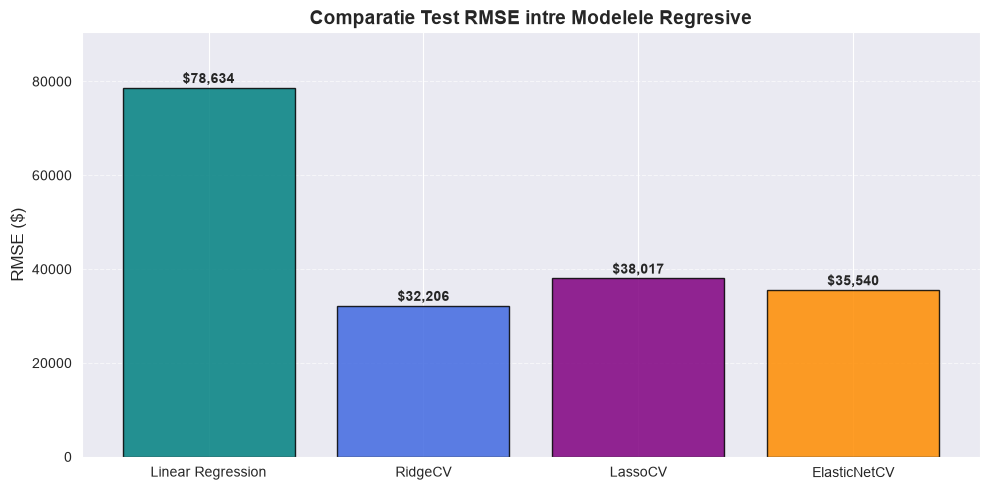

In [87]:
# Centralizarea rezultatelor intr-un tabel comparativ
comparison_table = pd.DataFrame({
    'Model': ['Linear Regression', 'RidgeCV', 'LassoCV', 'ElasticNetCV'],
    'Optimal Alpha': ['N/A', str(ridge_cv.alpha_), str(lasso_cv.alpha_), str(enet_cv.alpha_)],
    'Optimal L1 Ratio': ['N/A', '0.0 (L2)', '1.0 (L1)', str(enet_cv.l1_ratio_)],
    'Test RMSE ($)': [rmse_lr, rmse_ridge_cv, rmse_lasso_cv, rmse_enet_cv],
    'Nr. Coef. Nenuli': [len(linear_reg.coef_), len(ridge_cv.coef_), num_nonzero_lasso, num_nonzero_enet]
})

display(comparison_table)

# Reprezentare grafica comparativa a erorilor RMSE
plt.figure(figsize=(10, 5))
bars = plt.bar(comparison_table['Model'], comparison_table['Test RMSE ($)'],
               color=['teal', 'royalblue', 'purple', 'darkorange'], edgecolor='black', alpha=0.85)
plt.title('Comparatie Test RMSE intre Modelele Regresive', fontsize=14, fontweight='bold')
plt.ylabel('RMSE ($)', fontsize=12)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2.0, yval + 400, f"${yval:,.0f}", ha='center', va='bottom', fontweight='bold')
plt.ylim(0, max(comparison_table['Test RMSE ($)']) * 1.15)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

Putem, de asemenea, să realizăm un grafic al prețurilor reale și previzionate ale locuințelor, la fel ca înainte.

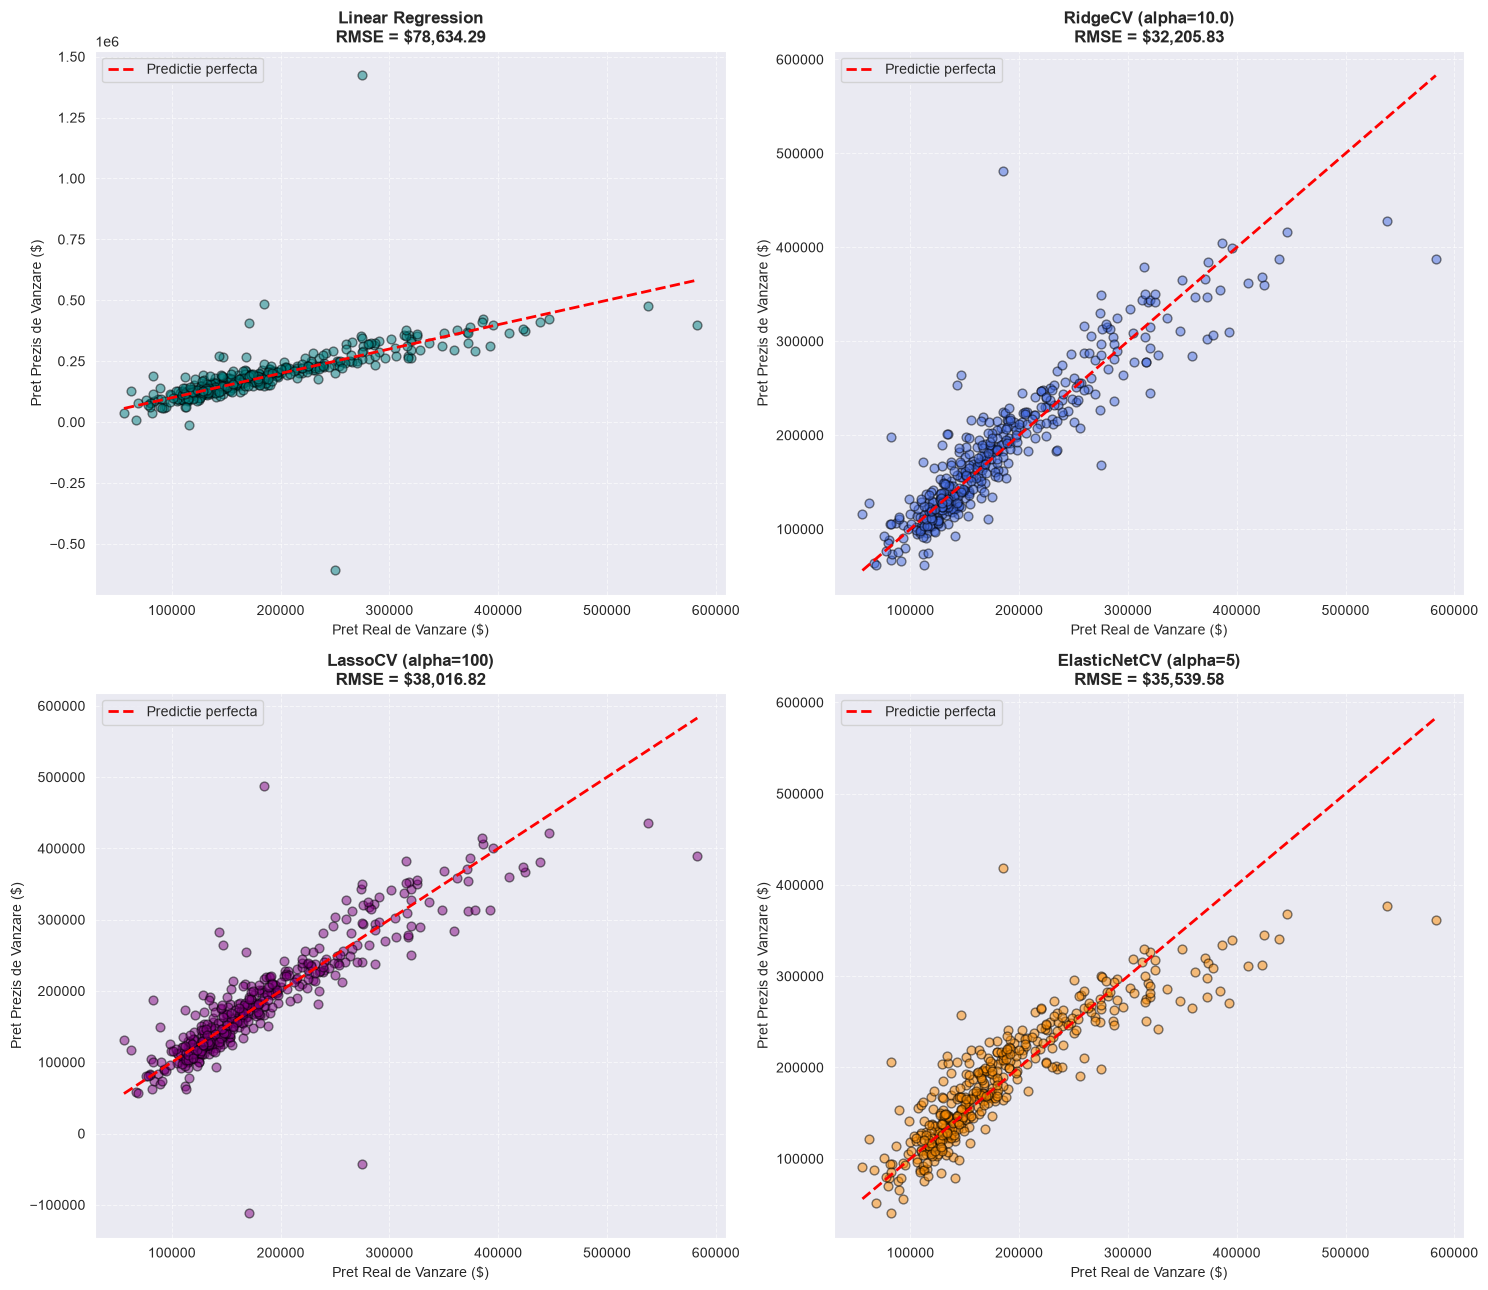

In [88]:
# Grafice comparative: Pret Real vs Pret Prezis pentru toate cele 4 modele
fig, axes = plt.subplots(2, 2, figsize=(15, 13))

models_data = [
    ('Linear Regression', y_pred_lr, rmse_lr, 'teal', axes[0, 0]),
    (f'RidgeCV (alpha={ridge_cv.alpha_})', y_pred_ridge_cv, rmse_ridge_cv, 'royalblue', axes[0, 1]),
    (f'LassoCV (alpha={lasso_cv.alpha_})', y_pred_lasso_cv, rmse_lasso_cv, 'purple', axes[1, 0]),
    (f'ElasticNetCV (alpha={enet_cv.alpha_})', y_pred_enet_cv, rmse_enet_cv, 'darkorange', axes[1, 1])
]

min_val = min(y_test.min(), y_pred_lr.min())
max_val = max(y_test.max(), y_pred_lr.max())

for title, preds, err, col, ax in models_data:
    ax.scatter(y_test, preds, alpha=0.5, color=col, edgecolor='black', s=40)
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2, label='Predictie perfecta')
    ax.set_title(f"{title}\nRMSE = ${err:,.2f}", fontsize=12, fontweight='bold')
    ax.set_xlabel('Pret Real de Vanzare ($)', fontsize=10)
    ax.set_ylabel('Pret Prezis de Vanzare ($)', fontsize=10)
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend(loc='upper left')

plt.tight_layout()
plt.show()

## Întrebarea 8

Să explorăm coborârea stochastică a gradientului în acest exercițiu.  
Reamintim că modelele liniare în general sunt sensibile la scalare.
Cu toate acestea, SGD este *foarte* sensibil la scalare.  
În plus, o valoare mare a ratei de învățare poate determina algoritmul să devieze, în timp ce o valoare prea mică poate dura prea mult până la convergență.

* Potriviți un model stochastic gradient descent fără o penalizare de regularizare (parametrul relevant este `penalty=None`).
* Ajustați acum modele stochastice de coborâre în gradient cu fiecare dintre cele trei penalizări (L2, L1, Elastic Net) folosind valorile parametrilor determinate prin validarea încrucișată de mai sus. 
* Nu scalați datele înainte de ajustarea modelului.  
* Comparați rezultatele cu cele obținute fără a utiliza coborârea stochastică în gradient.

In [89]:
alpha_sgd_l2 = ridge_cv.alpha_ / len(X_train)

sgd_none = SGDRegressor(penalty=None, random_state=42)
sgd_l2 = SGDRegressor(penalty='l2', alpha=alpha_sgd_l2, random_state=42)
sgd_l1 = SGDRegressor(penalty='l1', alpha=lasso_cv.alpha_, random_state=42)
sgd_enet = SGDRegressor(penalty='elasticnet', alpha=enet_cv.alpha_, l1_ratio=enet_cv.l1_ratio_, random_state=42)

sgd_models_unscaled = {
    'SGD (penalty=None)': sgd_none,
    'SGD (L2 / Ridge)': sgd_l2,
    'SGD (L1 / Lasso)': sgd_l1,
    'SGD (ElasticNet)': sgd_enet
}

rmses_unscaled = {}
for name, model in sgd_models_unscaled.items():
    try:
        model.fit(X_train, y_train)
        pred = model.predict(X_test)
        err = rmse(y_test, pred)
        rmses_unscaled[name] = err
    except Exception as e:
        rmses_unscaled[name] = np.nan

print("Erori RMSE pentru SGD pe date NESCALATE (eta0 implicit = 0.01):")
for name, err in rmses_unscaled.items():
    print(f"  {name}: RMSE = {err:e}")

Erori RMSE pentru SGD pe date NESCALATE (eta0 implicit = 0.01):
  SGD (penalty=None): RMSE = 5.831108e+15
  SGD (L2 / Ridge): RMSE = 1.352459e+14
  SGD (L1 / Lasso): RMSE = 7.533982e+14
  SGD (ElasticNet): RMSE = 3.824410e+15


Observați cât de mari sunt valorile erorii! Algoritmul este divergent. Acest lucru se poate datora faptului că scalarea și/sau rata de învățare sunt prea mari. Să ajustăm rata de învățare și să vedem ce se întâmplă.

* Introduceți `eta0=1e-7` la crearea instanței de `SGDRegressor`.
* Calculați din nou erorile pentru toate penalitățile și comparați.

In [90]:
# Antrenarea modelelor SGDRegressor pe date NESCALATE, dar cu rata de invatare foarte mica (eta0=1e-7)
sgd_eta_none = SGDRegressor(penalty=None, eta0=1e-7, max_iter=10000, random_state=42)
sgd_eta_l2 = SGDRegressor(penalty='l2', alpha=alpha_sgd_l2, eta0=1e-7, max_iter=10000, random_state=42)
sgd_eta_l1 = SGDRegressor(penalty='l1', alpha=lasso_cv.alpha_, eta0=1e-7, max_iter=10000, random_state=42)
sgd_eta_enet = SGDRegressor(penalty='elasticnet', alpha=enet_cv.alpha_, l1_ratio=enet_cv.l1_ratio_, eta0=1e-7, max_iter=10000, random_state=42)

sgd_models_eta = {
    'SGD (None, eta0=1e-7)': sgd_eta_none,
    'SGD (L2, eta0=1e-7)': sgd_eta_l2,
    'SGD (L1, eta0=1e-7)': sgd_eta_l1,
    'SGD (ElasticNet, eta0=1e-7)': sgd_eta_enet
}

rmses_eta = {}
for name, model in sgd_models_eta.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    err = rmse(y_test, pred)
    rmses_eta[name] = err

print("Erori RMSE pentru SGD pe date nescalate cu eta0=1e-7:")
for name, err in rmses_eta.items():
    print(f"  {name}: RMSE = ${err:,.2f}")

Erori RMSE pentru SGD pe date nescalate cu eta0=1e-7:
  SGD (None, eta0=1e-7): RMSE = $74,750.08
  SGD (L2, eta0=1e-7): RMSE = $74,750.08
  SGD (L1, eta0=1e-7): RMSE = $74,750.99
  SGD (ElasticNet, eta0=1e-7): RMSE = $74,750.27


Acum să ne scalăm datele de antrenament și să încercăm din nou.

* Adaptați un `MinMaxScaler` la `X_train` și creați o variabilă `X_train_scaled`.
* Folosind scala, transformați `X_test` și creați o variabilă `X_test_scaled`. 
* Aplicați-le aceleași versiuni ale SGD și comparați rezultatele. De data aceasta nu introduceți un eta0.

In [91]:
# 1. Scalarea caracteristicilor folosind MinMaxScaler [0, 1]
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. Antrenarea modelelor SGDRegressor pe date scalate cu eta0 implicit
sgd_scaled_none = SGDRegressor(penalty=None, max_iter=10000, random_state=42)
sgd_scaled_l2 = SGDRegressor(penalty='l2', alpha=alpha_sgd_l2, max_iter=10000, random_state=42)
sgd_scaled_l1 = SGDRegressor(penalty='l1', alpha=lasso_cv.alpha_, max_iter=10000, random_state=42)
sgd_scaled_enet = SGDRegressor(penalty='elasticnet', alpha=enet_cv.alpha_, l1_ratio=enet_cv.l1_ratio_, max_iter=10000, random_state=42)

sgd_models_scaled = {
    'SGD Scaled (None)': sgd_scaled_none,
    'SGD Scaled (L2 / Ridge)': sgd_scaled_l2,
    'SGD Scaled (L1 / Lasso)': sgd_scaled_l1,
    'SGD Scaled (ElasticNet)': sgd_scaled_enet
}

rmses_scaled = {}
for name, model in sgd_models_scaled.items():
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_test_scaled)
    err = rmse(y_test, pred)
    rmses_scaled[name] = err

print("Erori RMSE pentru SGD pe date SCALATE cu MinMaxScaler (eta0 implicit):")
for name, err in rmses_scaled.items():
    print(f"  {name}: RMSE = ${err:,.2f}")

Erori RMSE pentru SGD pe date SCALATE cu MinMaxScaler (eta0 implicit):
  SGD Scaled (None): RMSE = $32,674.90
  SGD Scaled (L2 / Ridge): RMSE = $32,261.64
  SGD Scaled (L1 / Lasso): RMSE = $32,380.94
  SGD Scaled (ElasticNet): RMSE = $43,763.66


In [92]:
# Tabel comparativ final pentru toate experimentele SGD
sgd_summary = pd.DataFrame({
    'Penalizare': ['Fara penalizare (None)', 'L2 (Ridge)', 'L1 (Lasso)', 'ElasticNet'],
    'Nescalat (eta0 implicit)': [
        f"{rmses_unscaled.get('SGD (penalty=None)', np.nan):.2e}",
        f"{rmses_unscaled.get('SGD (L2 / Ridge)', np.nan):.2e}",
        f"{rmses_unscaled.get('SGD (L1 / Lasso)', np.nan):.2e}",
        f"{rmses_unscaled.get('SGD (ElasticNet)', np.nan):.2e}"
    ],
    'Nescalat (eta0=1e-7)': [
        f"${rmses_eta.get('SGD (None, eta0=1e-7)', 0):,.2f}",
        f"${rmses_eta.get('SGD (L2, eta0=1e-7)', 0):,.2f}",
        f"${rmses_eta.get('SGD (L1, eta0=1e-7)', 0):,.2f}",
        f"${rmses_eta.get('SGD (ElasticNet, eta0=1e-7)', 0):,.2f}"
    ],
    'Scalat MinMaxScaler (eta0 implicit)': [
        f"${rmses_scaled.get('SGD Scaled (None)', 0):,.2f}",
        f"${rmses_scaled.get('SGD Scaled (L2 / Ridge)', 0):,.2f}",
        f"${rmses_scaled.get('SGD Scaled (L1 / Lasso)', 0):,.2f}",
        f"${rmses_scaled.get('SGD Scaled (ElasticNet)', 0):,.2f}"
    ]
})

display(sgd_summary)

,Penalizare,Nescalat (eta0 implicit),Nescalat (eta0=1e-7),Scalat MinMaxScaler (eta0 implicit)
0,Fara penalizare (None),5.83e+15,"$74,750.08","$32,674.90"
1,L2 (Ridge),1.35e+14,"$74,750.08","$32,261.64"
2,L1 (Lasso),7.53e+14,"$74,750.99","$32,380.94"
3,ElasticNet,3.82e+15,"$74,750.27","$43,763.66"
